# Photon Sum-Image Hyperspectral Analysis

This notebook analyzes final TIFFs generated as exact photon-number sum images, for example `*_sumImage_2to2.tiff` through `*_sumImage_100to100.tiff`.

Workflow:
1. Find matching photon-number images in each run folder.
2. Average corresponding photon-number images across runs.
3. Treat the averaged stack as a per-pixel photon-number histogram cube.
4. Visualize total event density, photon-number distribution, RGB band composites, HSV hyperspectral summaries, representative channels, and region spectra.


In [1]:
from pathlib import Path

# Set this to either a parent folder containing run folders, or one run folder.
experiment_path = Path('/data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge')

photon_min = 2
photon_max = 100

# Outputs are kept outside the run final/ folders.
analysis_dir = experiment_path / 'analysis' / 'photon_histogram_hypercube'
averaged_tiff_dir = analysis_dir / 'averaged_tiffs'
figure_dir = analysis_dir / 'figures'

save_averaged_tiffs = True
save_hypercube_tiff = True
save_figures = True

# Set to a small integer for quick preview plots on very large images.
# The full-resolution averaged TIFFs and hypercube are still generated.
preview_stride = 2

analysis_dir.mkdir(parents=True, exist_ok=True)
averaged_tiff_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

experiment_path, analysis_dir

(PosixPath('/data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge'),
 PosixPath('/data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube'))

In [2]:
import csv
import re
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import tifffile
from matplotlib import colors
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 220,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'image.cmap': 'magma',
})

SUMIMAGE_RE = re.compile(r'_sumImage_(\d+)to(\d+)\.(?:tif|tiff)$', re.IGNORECASE)


def parse_photon_number(path):
    match = SUMIMAGE_RE.search(path.name)
    if not match:
        return None
    n_min = int(match.group(1))
    n_max = int(match.group(2))
    if n_min != n_max:
        return None
    return n_min


def discover_run_folders(root):
    root = Path(root).expanduser().resolve()
    if (root / 'final').is_dir():
        return [root]
    runs = []
    for child in sorted(root.iterdir()):
        if child.is_dir() and (child / 'final').is_dir():
            runs.append(child)
    return runs


def discover_sumimage_files(root, photon_numbers, excluded_dir=None):
    photon_numbers = set(photon_numbers)
    excluded_dir = Path(excluded_dir).resolve() if excluded_dir is not None else None
    files_by_photon = defaultdict(list)
    run_folders = discover_run_folders(root)

    for run in run_folders:
        final_dir = run / 'final'
        for path in sorted(final_dir.glob('*_sumImage_*to*.tif*')):
            if excluded_dir is not None and excluded_dir in path.resolve().parents:
                continue
            n = parse_photon_number(path)
            if n in photon_numbers:
                files_by_photon[n].append(path)

    return run_folders, dict(sorted(files_by_photon.items()))


def robust_scale(image, low=1, high=99.7):
    arr = np.asarray(image, dtype=np.float32)
    finite = np.isfinite(arr)
    if not finite.any():
        return np.zeros(arr.shape, dtype=np.float32)
    lo, hi = np.percentile(arr[finite], [low, high])
    if hi <= lo:
        return np.zeros(arr.shape, dtype=np.float32)
    return np.clip((arr - lo) / (hi - lo), 0, 1).astype(np.float32)


def preview(image, stride=1):
    stride = max(1, int(stride))
    return image[::stride, ::stride]


def preview_rgb(image, stride=1):
    stride = max(1, int(stride))
    return image[::stride, ::stride, :]


def save_current_figure(name):
    if save_figures:
        path = figure_dir / name
        plt.savefig(path, bbox_inches='tight')
        print('Saved', path)


## 1. Discover And Average Matching TIFFs

For each photon number `N`, the notebook averages all matching `*_sumImage_NtoN.tiff` files across the discovered run folders. These averaged images are the channels of the photon histogram cube.

In [3]:
photon_numbers_requested = list(range(photon_min, photon_max + 1))
run_folders, files_by_photon = discover_sumimage_files(
    experiment_path,
    photon_numbers_requested,
    excluded_dir=analysis_dir,
)

print(f'Discovered {len(run_folders)} run folder(s).')
for run in run_folders:
    print(' ', run)

missing = [n for n in photon_numbers_requested if n not in files_by_photon]
if missing:
    print('Missing exact photon-number TIFFs:', missing)

print('\nFiles per photon number:')
for n in photon_numbers_requested:
    print(f'{n:2d}: {len(files_by_photon.get(n, []))}')

if not files_by_photon:
    raise FileNotFoundError('No matching *_sumImage_NtoN.tiff files found. Run dataReduct_sumImages.sh first.')

Discovered 6 run folder(s).
  /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/exp103_ZnSAg_25_15_Edge_00000
  /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/exp103_ZnSAg_25_15_Edge_00001
  /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/exp103_ZnSAg_25_15_Edge_00002
  /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/exp103_ZnSAg_25_15_Edge_00003
  /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/exp103_ZnSAg_25_15_Edge_00004
  /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/exp103_ZnSAg_25_15_Edge_00005

Files per photon number:
 2: 6
 3: 6
 4: 6
 5: 6
 6: 6
 7: 6
 8: 6
 9: 6
10: 6
11: 6
12: 6
13: 6
14: 6
15: 6
16: 6
17: 6
18: 6
19: 6
20: 6
21: 6
22: 6
23: 6
24: 6
25: 6
26: 6
27: 6
28: 6
29: 6
30: 6


In [4]:
def average_photon_images(files_by_photon, output_dir):
    photon_numbers = []
    averaged_images = []
    averaged_paths = {}
    expected_shape = None

    for n, paths in sorted(files_by_photon.items()):
        if len(paths) == 0:
            continue

        acc = None
        for path in paths:
            image = tifffile.imread(path).astype(np.float64, copy=False)
            if expected_shape is None:
                expected_shape = image.shape
            elif image.shape != expected_shape:
                raise ValueError(f'Shape mismatch for {path}: {image.shape} != {expected_shape}')

            if acc is None:
                acc = np.zeros(image.shape, dtype=np.float64)
            acc += image

        avg = (acc / len(paths)).astype(np.float32)
        photon_numbers.append(n)
        averaged_images.append(avg)

        out_path = output_dir / f'average_sumImage_{n}to{n}.tiff'
        averaged_paths[n] = out_path
        if save_averaged_tiffs:
            tifffile.imwrite(out_path, avg, metadata={'photon_number': n, 'averaged_input_count': len(paths)})
            print(f'Saved {out_path} from {len(paths)} file(s)')

    cube = np.stack(averaged_images, axis=0).astype(np.float32)
    return np.array(photon_numbers, dtype=np.float32), cube, averaged_paths


photon_numbers, counts_cube, averaged_paths = average_photon_images(files_by_photon, averaged_tiff_dir)
print('Cube shape:', counts_cube.shape, '(photon, y, x)')
print('Photon channels:', photon_numbers.astype(int).tolist())

if save_hypercube_tiff:
    cube_path = analysis_dir / 'photon_histogram_cube_CYX.tiff'
    tifffile.imwrite(
        cube_path,
        counts_cube,
        metadata={'axes': 'CYX', 'photon_numbers': photon_numbers.astype(int).tolist()},
    )
    print('Saved', cube_path)

Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/averaged_tiffs/average_sumImage_2to2.tiff from 6 file(s)
Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/averaged_tiffs/average_sumImage_3to3.tiff from 6 file(s)
Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/averaged_tiffs/average_sumImage_4to4.tiff from 6 file(s)
Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/averaged_tiffs/average_sumImage_5to5.tiff from 6 file(s)
Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/averaged_tiffs/average_sumImage_6to6.tiff from 6 file(s)
Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/averaged_tiffs/average_sumImage_7to7.tiff from 6 file(s)
Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histog

## 2. Derive Per-Pixel Histogram Features

`counts_cube[:, y, x]` is the photon-number histogram for one pixel. The derived maps below summarize that histogram as total events, mean photon number, dominant photon number, spectral concentration, and entropy.

In [5]:
eps = np.float32(1e-12)
photon_axis = photon_numbers[:, None, None].astype(np.float32)

total_events = counts_cube.sum(axis=0, dtype=np.float32)
weighted_sum = (counts_cube * photon_axis).sum(axis=0, dtype=np.float32)
mean_photon = np.divide(weighted_sum, total_events, out=np.zeros_like(total_events), where=total_events > 0)

dominant_index = counts_cube.argmax(axis=0)
dominant_photon = photon_numbers[dominant_index].astype(np.float32)
dominant_photon = np.where(total_events > 0, dominant_photon, np.nan)

max_fraction = np.divide(counts_cube.max(axis=0), total_events, out=np.zeros_like(total_events), where=total_events > 0)
prob_cube = np.divide(counts_cube, total_events[None, :, :] + eps, out=np.zeros_like(counts_cube), where=total_events[None, :, :] > 0)
entropy = -(prob_cube * np.log2(prob_cube + eps)).sum(axis=0, dtype=np.float32)
entropy_norm = entropy / np.log2(len(photon_numbers))

global_counts = counts_cube.reshape(counts_cube.shape[0], -1).sum(axis=1, dtype=np.float64)
global_fraction = global_counts / max(global_counts.sum(), 1)

summary_csv = analysis_dir / 'global_photon_histogram.csv'
with open(summary_csv, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['photon_number', 'event_count', 'fraction'])
    for n, count, frac in zip(photon_numbers.astype(int), global_counts, global_fraction):
        writer.writerow([int(n), float(count), float(frac)])

print('Saved', summary_csv)
print('Total averaged event count:', float(global_counts.sum()))

Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/global_photon_histogram.csv
Total averaged event count: 11288699.252216846


## 3. Hyperspectral Color Composites

Two composite views are useful:
- RGB bands: blue = low photon number, green = middle photon number, red = high photon number.
- HSV summary: hue = mean photon number, saturation = histogram concentration, value = total event density.

In [6]:
def band_sum(cube, photon_numbers, low, high):
    mask = (photon_numbers >= low) & (photon_numbers <= high)
    if not mask.any():
        return np.zeros(cube.shape[1:], dtype=np.float32)
    return cube[mask].sum(axis=0, dtype=np.float32)


low_band = band_sum(counts_cube, photon_numbers, 2, 5)
mid_band = band_sum(counts_cube, photon_numbers, 6, 12)
high_band = band_sum(counts_cube, photon_numbers, 13, 100)

rgb_band = np.dstack([
    np.sqrt(robust_scale(high_band)),
    np.sqrt(robust_scale(mid_band)),
    np.sqrt(robust_scale(low_band)),
]).astype(np.float32)

mean_norm = np.clip((mean_photon - photon_numbers.min()) / (photon_numbers.max() - photon_numbers.min()), 0, 1)
hue = (1 - mean_norm) * 0.66
saturation = np.clip(np.sqrt(max_fraction), 0, 1)
value = robust_scale(np.log1p(total_events), low=0.5, high=99.8)
hsv = np.dstack([hue, saturation, value])
rgb_hsv_summary = colors.hsv_to_rgb(hsv).astype(np.float32)

if save_hypercube_tiff:
    tifffile.imwrite(analysis_dir / 'hyperspectral_rgb_low_mid_high.tiff', (rgb_band * 65535).astype(np.uint16))
    tifffile.imwrite(analysis_dir / 'hyperspectral_hsv_summary_rgb.tiff', (rgb_hsv_summary * 65535).astype(np.uint16))
    tifffile.imwrite(analysis_dir / 'total_events.tiff', total_events.astype(np.float32))
    tifffile.imwrite(analysis_dir / 'mean_photon_number.tiff', mean_photon.astype(np.float32))
    tifffile.imwrite(analysis_dir / 'dominant_photon_number.tiff', np.nan_to_num(dominant_photon, nan=0).astype(np.float32))
    tifffile.imwrite(analysis_dir / 'photon_histogram_entropy.tiff', entropy_norm.astype(np.float32))
    print('Saved composite and feature TIFFs in', analysis_dir)

Saved composite and feature TIFFs in /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube


Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/figures/overview_hyperspectral_maps.png


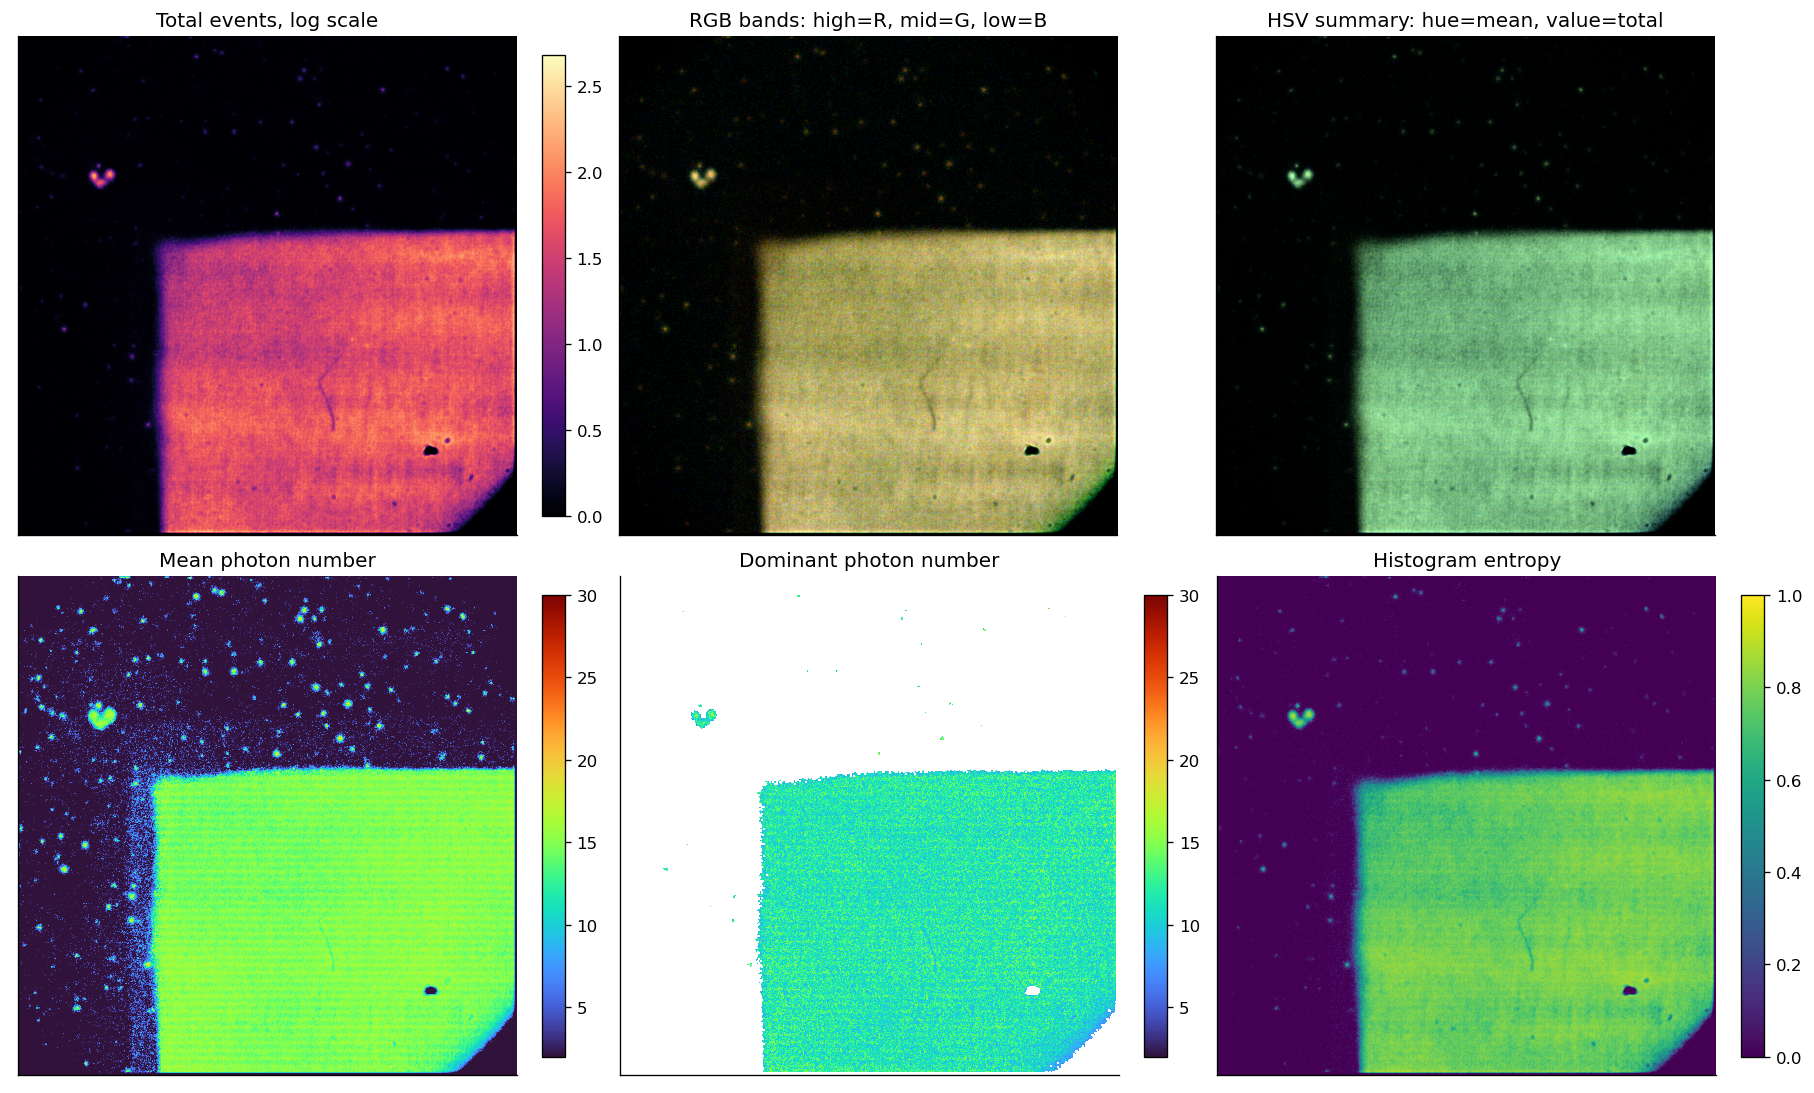

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)

im = axes[0, 0].imshow(preview(np.log1p(total_events), preview_stride), cmap='magma')
axes[0, 0].set_title('Total events, log scale')
fig.colorbar(im, ax=axes[0, 0], fraction=0.046)

axes[0, 1].imshow(preview_rgb(rgb_band, preview_stride))
axes[0, 1].set_title('RGB bands: high=R, mid=G, low=B')

axes[0, 2].imshow(preview_rgb(rgb_hsv_summary, preview_stride))
axes[0, 2].set_title('HSV summary: hue=mean, value=total')

im = axes[1, 0].imshow(preview(mean_photon, preview_stride), cmap='turbo', vmin=photon_numbers.min(), vmax=photon_numbers.max())
axes[1, 0].set_title('Mean photon number')
fig.colorbar(im, ax=axes[1, 0], fraction=0.046)

im = axes[1, 1].imshow(preview(dominant_photon, preview_stride), cmap='turbo', vmin=photon_numbers.min(), vmax=photon_numbers.max())
axes[1, 1].set_title('Dominant photon number')
fig.colorbar(im, ax=axes[1, 1], fraction=0.046)

im = axes[1, 2].imshow(preview(entropy_norm, preview_stride), cmap='viridis', vmin=0, vmax=1)
axes[1, 2].set_title('Histogram entropy')
fig.colorbar(im, ax=axes[1, 2], fraction=0.046)

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

save_current_figure('overview_hyperspectral_maps.png')
plt.show()

## 4. Global Histogram And Region Spectra

The bar plot shows the global event distribution by photon number. The region spectra compare bright pixels, low-photon pixels, high-photon pixels, and all nonzero pixels.

Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/figures/global_photon_histogram.png


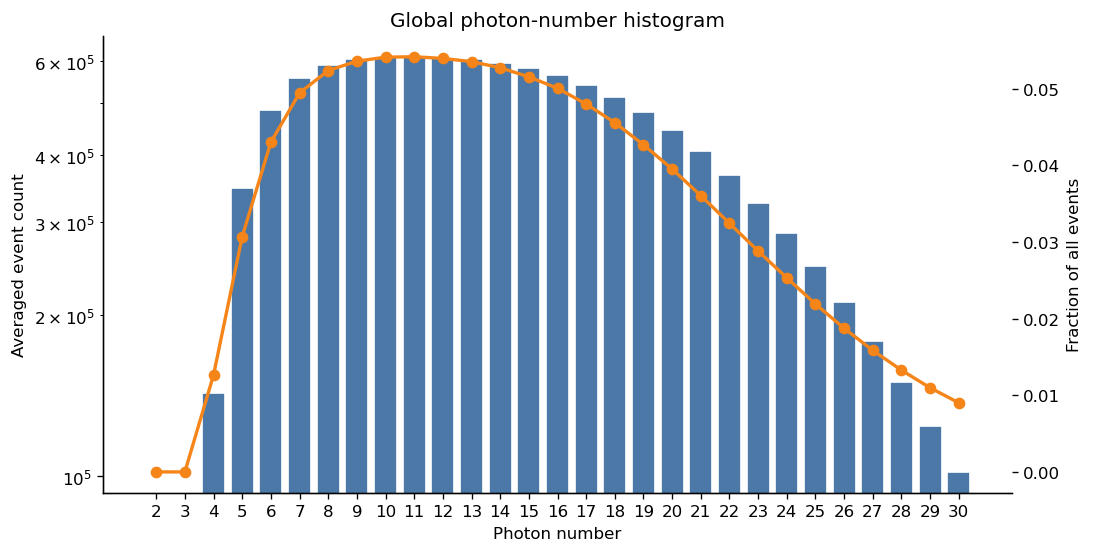

In [8]:
fig, ax1 = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax1.bar(photon_numbers, global_counts, width=0.8, color='#4c78a8', edgecolor='white')
ax1.set_xlabel('Photon number')
ax1.set_ylabel('Averaged event count')
ax1.set_yscale('log')
ax1.set_title('Global photon-number histogram')
ax1.set_xticks(photon_numbers.astype(int))

ax2 = ax1.twinx()
ax2.plot(photon_numbers, global_fraction, color='#f58518', marker='o', linewidth=2)
ax2.set_ylabel('Fraction of all events')

save_current_figure('global_photon_histogram.png')
plt.show()

Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/figures/region_photon_spectra.png


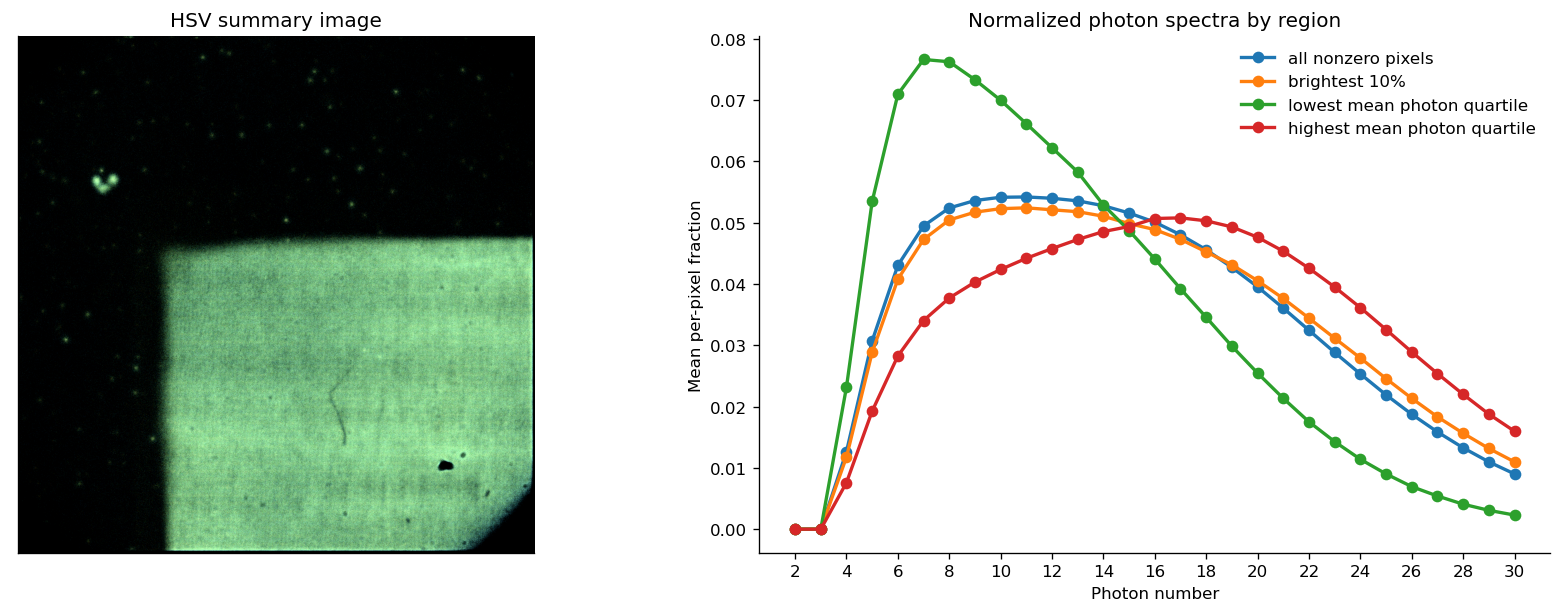

In [9]:
nonzero_mask = total_events > 0
bright_threshold = np.percentile(total_events[nonzero_mask], 90) if nonzero_mask.any() else np.inf
bright_mask = total_events >= bright_threshold

valid_mean = mean_photon[nonzero_mask]
low_threshold = np.percentile(valid_mean, 25) if valid_mean.size else -np.inf
high_threshold = np.percentile(valid_mean, 75) if valid_mean.size else np.inf
low_photon_mask = nonzero_mask & (mean_photon <= low_threshold)
high_photon_mask = nonzero_mask & (mean_photon >= high_threshold)

region_masks = {
    'all nonzero pixels': nonzero_mask,
    'brightest 10%': bright_mask,
    'lowest mean photon quartile': low_photon_mask,
    'highest mean photon quartile': high_photon_mask,
}

def normalized_region_spectrum(mask):
    if not mask.any():
        return np.zeros(len(photon_numbers), dtype=np.float64)
    spectrum = counts_cube[:, mask].mean(axis=1, dtype=np.float64)
    total = spectrum.sum()
    return spectrum / total if total > 0 else spectrum

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

axes[0].imshow(preview_rgb(rgb_hsv_summary, preview_stride))
axes[0].set_title('HSV summary image')
axes[0].set_xticks([])
axes[0].set_yticks([])

for name, mask in region_masks.items():
    axes[1].plot(photon_numbers, normalized_region_spectrum(mask), marker='o', linewidth=2, label=name)

axes[1].set_title('Normalized photon spectra by region')
axes[1].set_xlabel('Photon number')
axes[1].set_ylabel('Mean per-pixel fraction')
axes[1].set_xticks(photon_numbers.astype(int)[::2])
axes[1].legend(frameon=False)

save_current_figure('region_photon_spectra.png')
plt.show()

## 5. Representative Photon Channels

These maps show individual exact-photon-number channels after averaging across runs.

Saved /data01/data_acquisition/data/exp103_ZnSAg_25_15_Edge/analysis/photon_histogram_hypercube/figures/representative_photon_channels.png


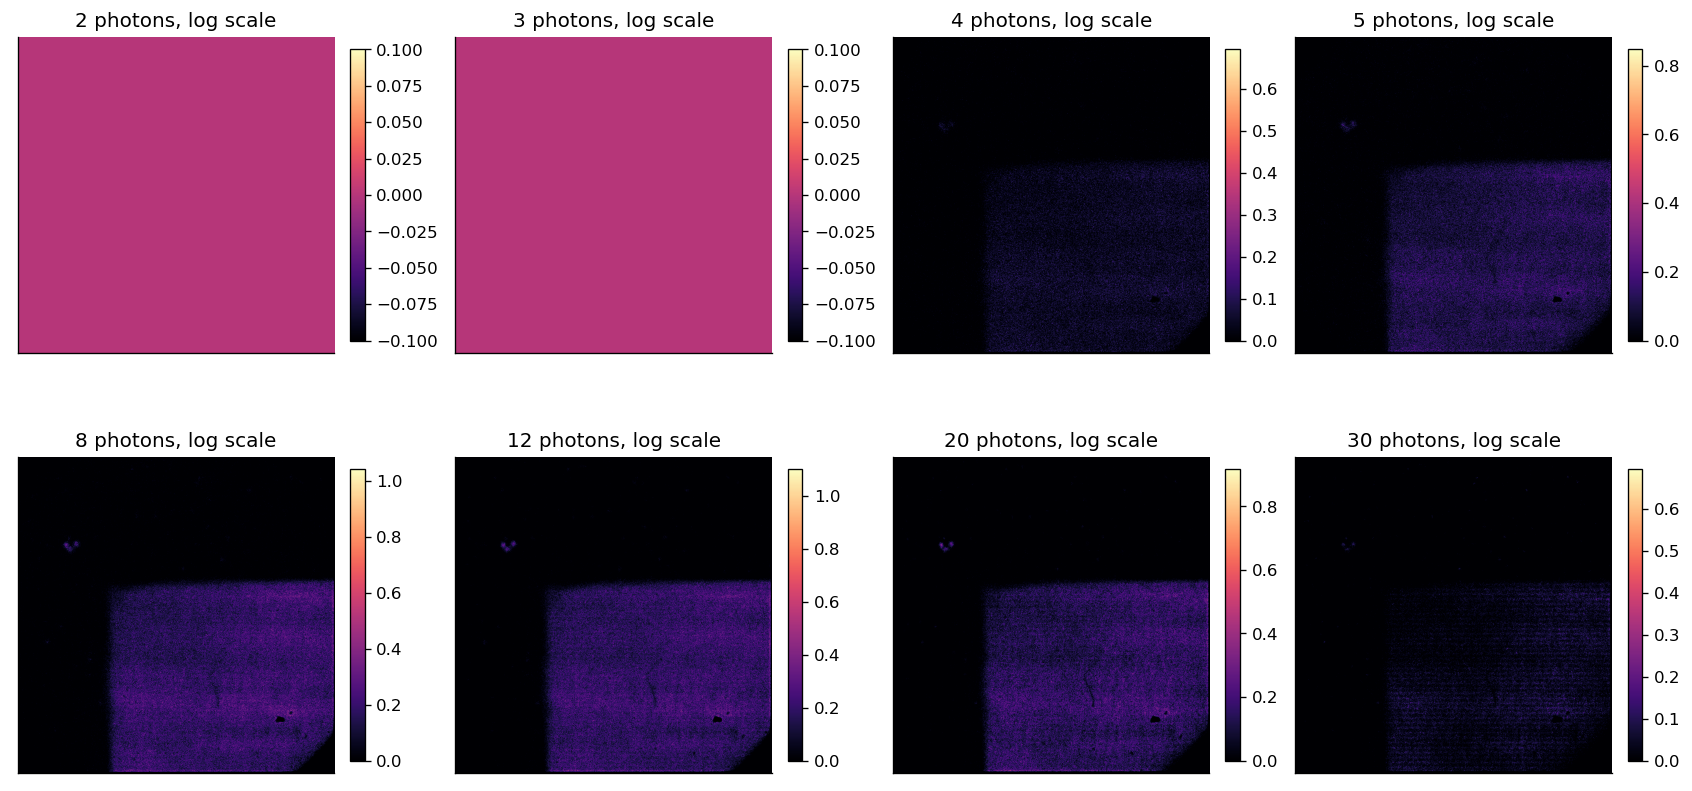

In [10]:
requested_channels = [2, 3, 4, 5, 8, 12, 20, 30, 50, 75, 100]
available_channels = [n for n in requested_channels if n in photon_numbers.astype(int)]

ncols = 4
nrows = int(np.ceil(len(available_channels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, n in zip(axes, available_channels):
    idx = int(np.where(photon_numbers.astype(int) == n)[0][0])
    image = counts_cube[idx]
    im = ax.imshow(preview(np.log1p(image), preview_stride), cmap='magma')
    ax.set_title(f'{n} photons, log scale')
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)

for ax in axes[len(available_channels):]:
    ax.axis('off')

save_current_figure('representative_photon_channels.png')
plt.show()

## 6. Interactive Channel Viewer

Use the slider to inspect any exact photon-number channel. This is useful for checking whether specific photon-count events have distinct spatial structure.

In [11]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    channel_slider = widgets.IntSlider(
        value=int(photon_numbers[0]),
        min=int(photon_numbers.min()),
        max=int(photon_numbers.max()),
        step=1,
        description='Photons',
        continuous_update=False,
    )

    def show_channel(n):
        matches = np.where(photon_numbers.astype(int) == int(n))[0]
        if len(matches) == 0:
            print(f'No averaged channel for {n} photons')
            return
        image = counts_cube[int(matches[0])]
        fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
        im = ax.imshow(preview(np.log1p(image), preview_stride), cmap='magma')
        ax.set_title(f'{n} photons, averaged image, log scale')
        ax.set_xticks([])
        ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046)
        plt.show()

    display(widgets.interactive_output(show_channel, {'n': channel_slider}))
    display(channel_slider)
except Exception as exc:
    print('Interactive viewer is unavailable:', exc)

Output()

IntSlider(value=2, continuous_update=False, description='Photons', max=30, min=2)

## 7. Output Files

Main outputs:
- `averaged_tiffs/average_sumImage_NtoN.tiff`: averaged exact-photon channel images.
- `photon_histogram_cube_CYX.tiff`: hyperspectral cube with axes `(photon, y, x)`.
- `global_photon_histogram.csv`: total event counts by photon number.
- `hyperspectral_rgb_low_mid_high.tiff`: low/mid/high photon-number RGB composite.
- `hyperspectral_hsv_summary_rgb.tiff`: HSV summary visualization.
- `total_events.tiff`, `mean_photon_number.tiff`, `dominant_photon_number.tiff`, `photon_histogram_entropy.tiff`: scalar feature maps.
- `figures/*.png`: publication-ready overview plots.